# 02. RQ2 — 참여업체 수와 업체별 금액 집중도(HHI)는 어떻게 달라졌는가?

- 분석 기간: 2017~2025년 (부분 연도인 2016·2026년 제외)
- 분석 대상: 벤처실적유형코드 3(물납 = 실제 납품)
  - 주문(코드 2)은 여러 해 물량을 한 번에 주문할 수 있어 연도별 실적이 왜곡될 수 있다
- 업체 식별: 벤처업체번호 (업체명은 표기 변형이 있음)
- 전처리 결과 `df`를 건드리지 않도록 분석용 데이터는 `df1`로 둔다

In [1]:
import sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.append("..")
from src.concentration import concentration, hhi_grade, trend_table, FIRM, AMT

SRC = "../data/조달청_벤처나라_전처리결과.csv"
FIG = "../figures/python/"
OUT = "../results/"
YEARS = range(2017, 2026)

plt.rcParams["font.family"] = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "Noto Sans CJK KR")
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 250, "display.max_columns", 30)

df1 = pd.read_csv(SRC, encoding="utf-8-sig", parse_dates=["실적일자"])
df1["연도"] = df1["실적일자"].dt.year
df1 = df1[df1[AMT] > 0]                               # 음수/0 금액 방어
n_all = len(df1)
df1 = df1[df1["연도"].between(2017, 2025)]            # 부분 연도(2016, 2026) 제외
n_year = len(df1)
df1_all = df1.copy()                                  # 실적유형 비교용 (주문+물납)
df1 = df1[df1["벤처실적유형코드"] == 3]                 # 물납실적(실제 납품)만 사용
print(f"분석 대상: {n_all:,}행 → {n_year:,}행(2017~2025) → {len(df1):,}행(물납)")
print("기간:", df1["실적일자"].min().date(), "~", df1["실적일자"].max().date())

# 업체 식별 기준 확인: 같은 벤처업체번호에 업체명이 여러 개인 경우
multi_name = df1_all.groupby(FIRM)["업체명"].nunique()
print("업체명이 2개 이상인 벤처업체번호:", int((multi_name > 1).sum()), "개 → 업체 집계는 벤처업체번호 기준")

분석 대상: 52,210행 → 47,170행(2017~2025) → 30,172행(물납)
기간: 2017-01-05 ~ 2025-12-31
업체명이 2개 이상인 벤처업체번호: 14 개 → 업체 집계는 벤처업체번호 기준


## 1. 지표 정의

```
HHI = Σ (업체별 금액 점유율 %)²     # 0(완전 분산) ~ 10,000(1개 업체 독점)
```

| 지표 | 정의 | 보는 이유 |
|---|---|---|
| HHI | 점유율 제곱의 합 | 전체 쏠림을 하나의 점수로 |
| CR1·CR3·CR10 | 상위 1·3·10개 업체 점유율 합 | 상위 몇 곳이 몇 %인지 |
| 유효업체수 | 10,000 ÷ HHI | 몇 개 업체가 균등하게 나눈 것과 같은가 |
| 정규화 HHI | 업체 수 효과를 뺀 0~1 값 | 업체 수가 다른 연도 비교 |
| 업체당 평균 vs 중앙값 | 두 값의 차이 | 소수 대형 업체가 평균을 끌어올리는지 |

등급은 미국 DOJ/FTC 가이드라인 3단계(비집중 < 1,000 / 중간집중 1,000~1,800 / 고집중 > 1,800)를 참고했다. 함수는 `src/concentration.py`에 있다.

## 2. 연도별 지표

In [2]:
yearly = df1.groupby("연도").apply(concentration, include_groups=False)
yearly["집중도등급"] = yearly["HHI"].map(hhi_grade)
yearly["참여업체수_증감률(%)"] = yearly["참여업체수"].pct_change() * 100
yearly["HHI_증감"] = yearly["HHI"].diff()

# 진입/퇴출 업체 (전년 대비)
firms_by_year = df1.groupby("연도")[FIRM].apply(set)
yrs = firms_by_year.index.tolist()
yearly["신규진입"] = [np.nan] + [len(firms_by_year[y] - firms_by_year[p]) for p, y in zip(yrs, yrs[1:])]
yearly["퇴출"] = [np.nan] + [len(firms_by_year[p] - firms_by_year[y]) for p, y in zip(yrs, yrs[1:])]
yearly["유지"] = [np.nan] + [len(firms_by_year[y] & firms_by_year[p]) for p, y in zip(yrs, yrs[1:])]

print("[표1] 연도별 참여업체 수 · 집중도")
yearly.round(2)

[표1] 연도별 참여업체 수 · 집중도


,참여업체수,거래건수,총실적금액(억원),업체당평균(백만원),업체당중앙값(백만원),HHI,정규화HHI,유효업체수(1/HHI),CR1(%),CR3(%),CR10(%),상위10%업체점유(%),집중도등급,참여업체수_증감률(%),HHI_증감,신규진입,퇴출,유지
연도,,,,,,,,,,,,,,,,,,
2017,46.0,395.0,54.28,118.00,17.91,1701.08,0.15,5.88,36.10,59.50,85.71,70.59,중간집중(1000~1800),NaN,NaN,NaN,NaN,NaN
2018,138.0,884.0,117.85,85.40,17.57,334.47,0.03,29.90,7.28,20.52,49.41,60.17,비집중(<1000),200.00,-1366.61,103.0,11.0,35.0
2019,246.0,1957.0,401.56,163.24,22.95,344.06,0.03,29.07,8.04,23.31,48.43,71.55,비집중(<1000),78.26,9.58,166.0,58.0,80.0
2020,444.0,3375.0,879.74,198.14,31.37,326.04,0.03,30.67,9.99,25.92,45.29,75.36,비집중(<1000),80.49,-18.02,289.0,91.0,155.0
2021,554.0,4455.0,1333.91,240.78,33.07,405.46,0.04,24.66,15.77,28.21,45.70,76.15,비집중(<1000),24.77,79.42,300.0,190.0,254.0
2022,587.0,5000.0,1721.38,293.25,38.67,401.51,0.04,24.91,14.92,26.38,50.47,78.38,비집중(<1000),5.96,-3.95,276.0,243.0,311.0
2023,643.0,5059.0,1527.51,237.56,31.94,214.61,0.02,46.60,6.47,18.17,39.16,75.54,비집중(<1000),9.54,-186.90,296.0,240.0,347.0
2024,693.0,4885.0,1345.16,194.11,37.04,222.63,0.02,44.92,10.28,20.30,34.76,70.68,비집중(<1000),7.78,8.02,321.0,271.0,372.0
2025,513.0,4162.0,1482.37,288.96,50.57,167.90,0.01,59.56,6.31,14.98,32.49,69.87,비집중(<1000),-25.97,-54.72,178.0,358.0,335.0


- 2017년: 업체 46개, 1위가 36%를 가져간 중간집중 시장(HHI 1,701)
- 2018년 HHI 334로 급락한 뒤 170~400 사이 유지, 2025년 168(유효업체수 약 60개)로 최저
- 2025년 업체 693 → 513개: 퇴출 358개가 신규 178개를 넘었다

### 2-1. 2025년에 빠진 업체는 어떤 업체였나
2024년에 물납 실적이 있었던 업체를 2025년에도 남은 업체와 빠진 업체로 나눠, 2024년 금액을 비교한다.

In [3]:
amt24 = df1[df1["연도"] == 2024].groupby(FIRM)[AMT].sum()
firms25 = firms_by_year[2025]
stay = amt24[amt24.index.isin(firms25)]
exit_ = amt24[~amt24.index.isin(firms25)]

cmp_exit = pd.DataFrame({
    "업체 수": [len(stay), len(exit_)],
    "2024년 금액 중앙값(억원)": [stay.median() / 1e8, exit_.median() / 1e8],
    "2024년 금액 합계(억원)": [stay.sum() / 1e8, exit_.sum() / 1e8],
    "2024년 금액 비중(%)": [stay.sum() / amt24.sum() * 100, exit_.sum() / amt24.sum() * 100],
}, index=["2025년 잔류", "2025년 퇴출"])
cmp_exit.round(2)

,업체 수,2024년 금액 중앙값(억원),2024년 금액 합계(억원),2024년 금액 비중(%)
2025년 잔류,335,0.76,943.06,70.11
2025년 퇴출,358,0.16,402.10,29.89


빠진 업체의 2024년 금액 중앙값은 남은 업체보다 훨씬 작았다. 즉 주로 소액 업체가 빠졌다. 다만 빠진 이유(폐업, 다른 경로 판매 등)는 이 데이터만으로 알 수 없다.

## 3. 추세검정 (+ 2017년 제외 민감도)

HHI는 1년에 값이 하나라 검정에 쓰는 점이 9개뿐이다. Spearman(방향의 일관성)과 선형회귀(연간 변화 크기)를 함께 보고, 두 방법 모두 p<0.05면 '유의', 하나만 또는 둘 다 p<0.10이면 '경향'으로 판정한다. 튀는 해인 2017년을 빼고도 같은 결론이 나오는지 함께 확인한다.

In [4]:
trend = trend_table(yearly)
print(f"[표2] 추세 검정 ({min(YEARS)}~{max(YEARS)})")
print(trend.to_string())

trend_ex17 = trend_table(yearly.loc[2018:])
print("\n[표2-1] 추세 검정 (2018~2025, 2017 제외)")
print(trend_ex17.to_string())

rho, p = stats.spearmanr(yearly["참여업체수"], yearly["HHI"])
print(f"\n참여업체수 vs HHI 상관: Spearman ρ={rho:+.3f} (p={p:.4f})")

[표2] 추세 검정 (2017~2025)
              Spearman ρ  Spearman p  기울기(/년)    선형 p      결론
지표                                                           
참여업체수              0.833      0.0053    74.50  0.0017  유의한 증가
HHI               -0.717      0.0298  -110.86  0.0629   감소 경향
정규화HHI            -0.683      0.0424    -0.01  0.0723   감소 경향
CR3(%)            -0.667      0.0499    -3.14  0.0552   감소 경향
유효업체수(1/HHI)       0.717      0.0298     4.82  0.0038  유의한 증가

[표2-1] 추세 검정 (2018~2025, 2017 제외)
              Spearman ρ  Spearman p  기울기(/년)    선형 p         결론
지표                                                              
참여업체수              0.762      0.0280    65.36  0.0115     유의한 증가
HHI               -0.595      0.1195   -25.14  0.0588  뚜렷한 추세 없음
정규화HHI            -0.548      0.1600    -0.00  0.1686  뚜렷한 추세 없음
CR3(%)            -0.524      0.1827    -0.94  0.1983  뚜렷한 추세 없음
유효업체수(1/HHI)       0.595      0.1195     3.99  0.0239      증가 경향

참여업체수 vs HHI 상관: Spearman ρ=-0.450 (p=0.2242)


- 참여업체 수 증가는 2017년을 빼도 유의하다.
- HHI·CR3 감소는 2017년을 빼면 유의성이 사라진다 → "계속 감소"가 아니라 "2018년 급락 후 저집중 유지"로 해석한다.
- 업체 수와 HHI의 직접 관계는 유의하지 않아 인과 해석은 하지 않는다.

## 4. 산업군별 업체 수 · HHI

전체 HHI는 서로 경쟁하지 않는 산업을 한 시장으로 합쳐 낮게 나오는 효과가 있어, 42개 대분류 산업군별로 다시 계산한다. 업체가 적으면 HHI가 과대 계산되므로 2019~2025년 매년 업체 5개 이상인 산업군만 비교한다.

In [5]:
ind = (df1.groupby(["대분류_산업군명", "연도"]).apply(concentration, include_groups=False)
         [["참여업체수", "HHI", "CR3(%)"]].reset_index())
ind_hhi = ind.pivot(index="대분류_산업군명", columns="연도", values="HHI")
ind_n = ind.pivot(index="대분류_산업군명", columns="연도", values="참여업체수")

# 산업군별 연도 업체 수 (기준 연도 선정 근거)
firm_cnt = ind_n.fillna(0).astype(int)
firm_cnt = firm_cnt.loc[firm_cnt[2025].sort_values(ascending=False).index]
print("[업체 5개 이상 산업군 수 (연도별)]")
print((firm_cnt >= 5).sum().to_frame("산업군 수").T.to_string())
print("\n[산업군별 연도 참여업체 수] 상위 15개")
firm_cnt.head(15)

[업체 5개 이상 산업군 수 (연도별)]
연도     2017  2018  2019  2020  2021  2022  2023  2024  2025
산업군 수     1    13    18    23    26    26    26    27    22

[산업군별 연도 참여업체 수] 상위 15개


연도,2017,2018,2019,2020,2021,2022,2023,2024,2025
대분류_산업군명,,,,,,,,,
"구조물, 난방·공조·배관 설비 및 자재",3,21,36,56,85,84,111,134,118
"안전, 보안, 소방 및 통신·네트워크 장비",2,11,24,69,74,79,91,85,74
정보통신(IT) 장비 및 소프트웨어,4,9,23,43,45,64,58,58,45
산업용 기계 및 장비,6,16,16,32,48,52,64,63,40
"전기, 전자 기기 및 배전반",4,8,13,18,23,24,27,27,30
"청소, 세탁, 환경 및 폐기물 처리 장비",2,9,10,25,31,27,27,34,26
스포츠 및 레저 용품,1,2,7,15,11,18,14,22,21
"출판물, 인쇄물 및 사무용 소모품",1,5,7,19,17,21,26,30,20
기타 물품,0,0,1,2,9,13,23,25,20


In [6]:
# 산업군별 연도 HHI + 추세 (2019~2025 매년 업체 5개 이상인 산업군)
yrs_ind = list(range(2019, 2026))
keep = ind_n[yrs_ind].fillna(0).min(axis=1) >= 5
hhi_year = ind_hhi.loc[keep, yrs_ind].round(0)
for i, r in hhi_year.iterrows():
    rho, p = stats.spearmanr(yrs_ind, r.values)
    hhi_year.loc[i, "ρ"] = round(rho, 2)
    hhi_year.loc[i, "p"] = round(p, 3)
    hhi_year.loc[i, "추세"] = (("감소" if rho < 0 else "증가") if p < 0.05
                              else ("감소 경향" if rho < 0 else "증가 경향") if p < 0.10 else "뚜렷한 추세 없음")
hhi_year = hhi_year.sort_values("ρ")
print("[산업군별 연도 HHI + 추세 (2019~2025, 매년 업체 5개 이상)]")
hhi_year

[산업군별 연도 HHI + 추세 (2019~2025, 매년 업체 5개 이상)]


연도,2019,2020,2021,2022,2023,2024,2025,ρ,p,추세
대분류_산업군명,,,,,,,,,,
"교육, 훈련 및 복지 용품",5517.0,8413.0,7542.0,5958.0,5172.0,2716.0,1362.0,-0.79,0.036,감소
"구조물, 난방·공조·배관 설비 및 자재",1686.0,1501.0,2654.0,2457.0,887.0,842.0,656.0,-0.71,0.071,감소 경향
가구 및 실내장식,8845.0,6625.0,4436.0,5117.0,2571.0,1873.0,5641.0,-0.61,0.148,뚜렷한 추세 없음
"청소, 세탁, 환경 및 폐기물 처리 장비",7882.0,2716.0,1753.0,2634.0,5058.0,1190.0,1754.0,-0.57,0.180,뚜렷한 추세 없음
산업용 기계 및 장비,1682.0,1263.0,1076.0,626.0,718.0,678.0,1245.0,-0.54,0.215,뚜렷한 추세 없음
"안전, 보안, 소방 및 통신·네트워크 장비",2176.0,594.0,2341.0,1641.0,1283.0,501.0,858.0,-0.50,0.253,뚜렷한 추세 없음
정보통신(IT) 장비 및 소프트웨어,2946.0,1418.0,2300.0,1922.0,2494.0,2239.0,817.0,-0.46,0.294,뚜렷한 추세 없음
"전기, 전자 기기 및 배전반",3745.0,1701.0,4611.0,1530.0,1449.0,1991.0,2817.0,-0.25,0.589,뚜렷한 추세 없음
자재취급장비,2882.0,2550.0,1627.0,1452.0,3210.0,2138.0,2689.0,0.00,1.000,뚜렷한 추세 없음


- 지속적으로 분산된 산업은 교육·복지용품(유의한 감소)과 구조물·공조 설비(감소 경향) 2개뿐이다.
- 나머지 13개는 대형 계약 몇 건에 HHI가 크게 출렁였고, 2025년 기준 15개 중 12개가 HHI 1,000 이상이다.

### 4-1. 제외한 소규모 산업군 확인
연도별 업체 수가 한 번도 3개를 넘지 않은 산업군에서, 같은 업체가 반복 납품하는지 벤처업체번호로 확인한다.

In [7]:
small = firm_cnt[firm_cnt.max(axis=1) <= 3].index
sub = df1[df1["대분류_산업군명"].isin(small)]

firm_years = (sub.groupby(["대분류_산업군명", "벤처업체번호", "업체명"])["연도"]
                 .apply(lambda x: sorted(set(x))).reset_index(name="등장연도"))
firm_years["등장연도수"] = firm_years["등장연도"].str.len()

summary = sub.groupby("대분류_산업군명").agg(
    고유업체수=("벤처업체번호", "nunique"),
    거래건수=("실적금액", "size"),
    금액_억원=("실적금액", lambda x: round(x.sum() / 1e8, 2)),
)
summary["2년이상_등장업체"] = firm_years[firm_years["등장연도수"] >= 2].groupby("대분류_산업군명").size()
summary = summary.fillna(0).astype({"2년이상_등장업체": int}).sort_values("고유업체수", ascending=False)

print(f"[소규모 산업군 요약] {len(small)}개 산업군, 금액 비중 {sub[AMT].sum() / df1[AMT].sum() * 100:.1f}%")
summary

[소규모 산업군 요약] 13개 산업군, 금액 비중 0.5%


,고유업체수,거래건수,금액_억원,2년이상_등장업체
대분류_산업군명,,,,
신발 및 가죽제품,5,46,4.55,2
"엔진, 터빈 및 부품",4,4,2.32,0
연구개발서비스,4,29,2.15,3
수산용기계,3,49,23.25,2
교육훈련서비스,3,14,3.30,0
엔지니어링서비스,3,10,2.24,2
악기,2,11,0.49,1
폐기물처리서비스,2,7,1.36,1
건물건설 및 시설유지보수서비스,1,23,2.63,1


## 5. (참고) 실적유형별 HHI · CR10
분석은 물납 기준이지만, 주문·전체 기준으로도 같은 방향인지 확인한다.

In [8]:
TYPE = {"전체": df1_all, "주문(0002)": df1_all[df1_all["벤처실적유형코드"] == 2], "물납(0003)": df1}
by_type = pd.concat({k: v.groupby("연도").apply(concentration, include_groups=False)[["HHI", "CR10(%)"]]
                     for k, v in TYPE.items()}, axis=1)
by_type.round(2)

전체         주문(0002)         물납(0003)        
          HHI CR10(%)      HHI CR10(%)      HHI CR10(%)
연도                                                     
2017  1416.26   80.30   662.86   71.90  1701.08   85.71
2018   259.19   43.12   463.23   54.07   334.47   49.41
2019   241.46   40.35   157.91   29.25   344.06   48.43
2020   254.41   39.63   154.79   30.27   326.04   45.29
2021   333.91   41.25   129.83   26.68   405.46   45.70
2022   347.63   46.81   115.60   24.57   401.51   50.47
2023   184.74   36.05    95.60   23.06   214.61   39.16
2024   184.75   31.37    94.73   22.45   222.63   34.76
2025   134.26   28.49   140.95   25.03   167.90   32.49

## 6. 시각화

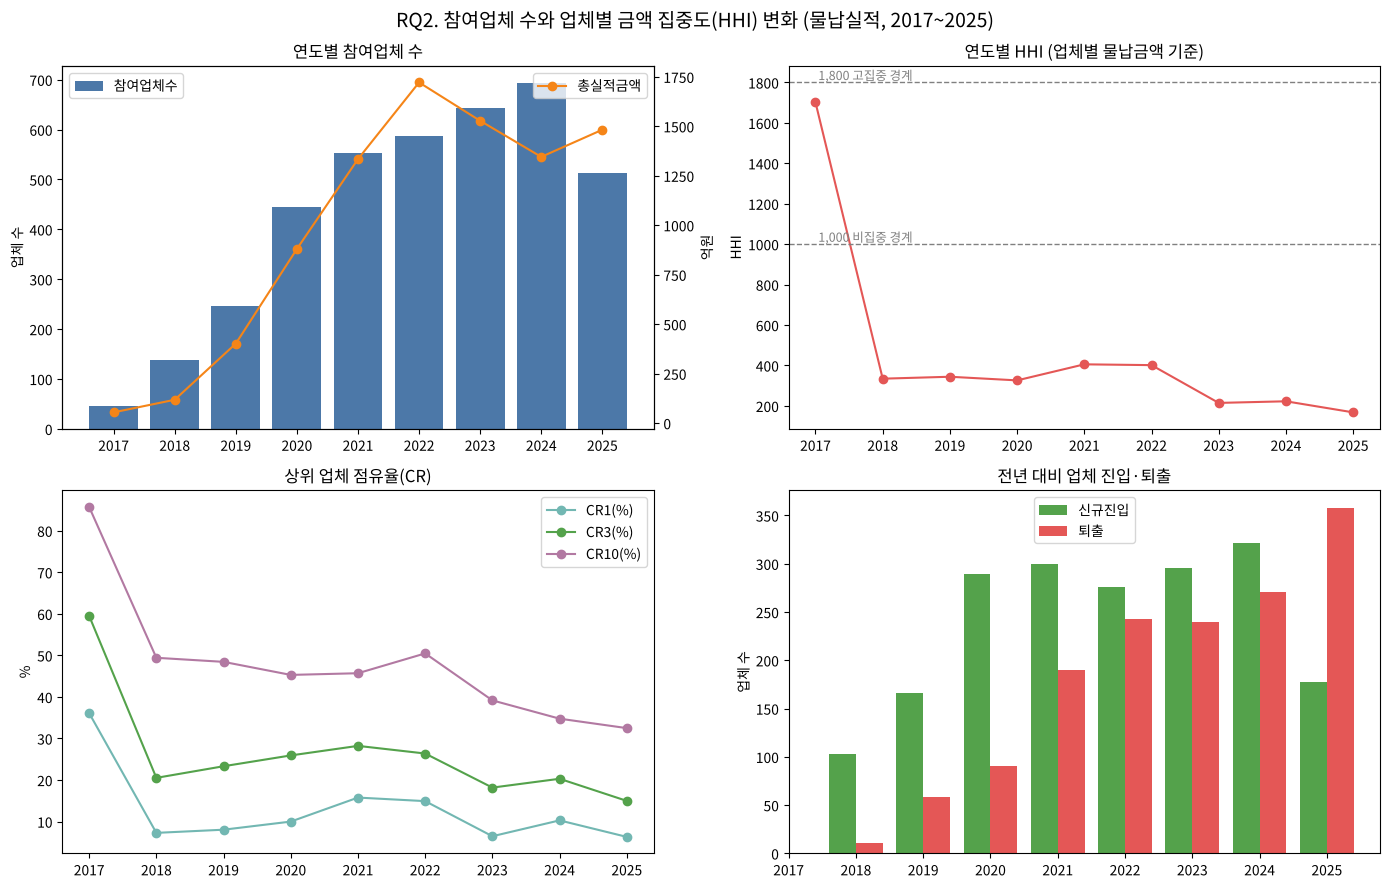

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
x = yearly.index

a = ax[0, 0]
a.bar(x, yearly["참여업체수"], color="#4C78A8", label="참여업체수")
a.set_title("연도별 참여업체 수"); a.set_ylabel("업체 수")
a2 = a.twinx(); a2.plot(x, yearly["총실적금액(억원)"], "o-", color="#F58518", label="총실적금액")
a2.set_ylabel("억원")
a.legend(loc="upper left"); a2.legend(loc="upper right")

a = ax[0, 1]
a.plot(x, yearly["HHI"], "o-", color="#E45756")
a.axhline(1000, ls="--", c="gray", lw=1); a.axhline(1800, ls="--", c="gray", lw=1)
a.text(x.min(), 1000, " 1,000 비집중 경계", va="bottom", fontsize=9, c="gray")
a.text(x.min(), 1800, " 1,800 고집중 경계", va="bottom", fontsize=9, c="gray")
a.set_title("연도별 HHI (업체별 물납금액 기준)"); a.set_ylabel("HHI")

a = ax[1, 0]
for c, col in zip(["CR1(%)", "CR3(%)", "CR10(%)"], ["#72B7B2", "#54A24B", "#B279A2"]):
    a.plot(x, yearly[c], "o-", label=c, color=col)
a.set_title("상위 업체 점유율(CR)"); a.set_ylabel("%"); a.legend()

a = ax[1, 1]
a.bar(x - 0.2, yearly["신규진입"], 0.4, label="신규진입", color="#54A24B")
a.bar(x + 0.2, yearly["퇴출"], 0.4, label="퇴출", color="#E45756")
a.set_title("전년 대비 업체 진입·퇴출"); a.set_ylabel("업체 수"); a.legend()

for a in ax.flat:
    a.set_xticks(x)
fig.suptitle("RQ2. 참여업체 수와 업체별 금액 집중도(HHI) 변화 (물납실적, 2017~2025)", fontsize=14)
fig.tight_layout(); fig.savefig(FIG + "rq2_yearly_firms_hhi.png", dpi=150)
plt.show()

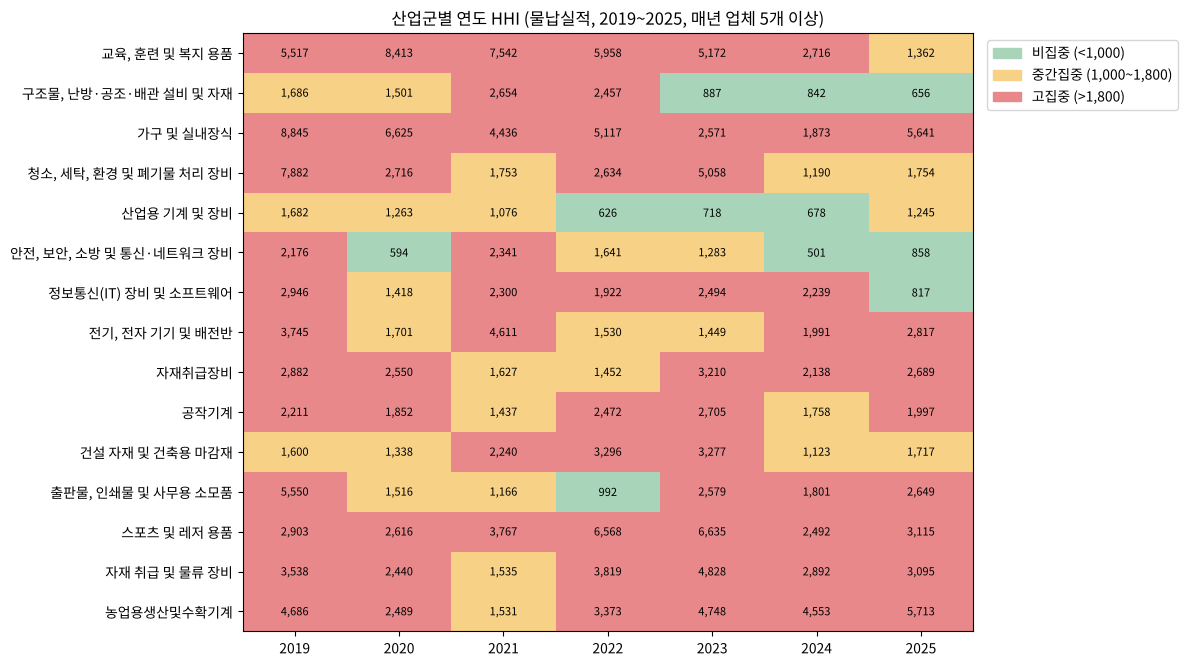

In [10]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

hm = hhi_year[yrs_ind]
cmap = ListedColormap(["#A8D5BA", "#F6D186", "#E8888A"])        # 비집중 / 중간집중 / 고집중
norm = BoundaryNorm([0, 1000, 1800, 10001], cmap.N)
fig2, axh = plt.subplots(figsize=(12, max(4, 0.45 * len(hm))))
axh.imshow(hm.values, cmap=cmap, norm=norm, aspect="auto")
axh.set_xticks(range(len(yrs_ind)), yrs_ind); axh.set_yticks(range(len(hm)), hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        axh.text(j, i, f"{hm.values[i, j]:,.0f}", ha="center", va="center", fontsize=8)
axh.legend(handles=[Patch(color=c, label=l) for c, l in
                    zip(cmap.colors, ["비집중 (<1,000)", "중간집중 (1,000~1,800)", "고집중 (>1,800)"])],
           loc="upper left", bbox_to_anchor=(1.01, 1))
axh.set_title("산업군별 연도 HHI (물납실적, 2019~2025, 매년 업체 5개 이상)")
fig2.tight_layout(); fig2.savefig(FIG + "rq2_industry_hhi_heatmap.png", dpi=150)
plt.show()

## 7. 결과 저장

In [11]:
yearly.round(4).to_csv(OUT + "rq2_yearly_concentration.csv", encoding="utf-8-sig")
trend.to_csv(OUT + "rq2_trend_test.csv", encoding="utf-8-sig")
trend_ex17.to_csv(OUT + "rq2_trend_test_excl2017.csv", encoding="utf-8-sig")
firm_cnt.to_csv(OUT + "rq2_industry_firm_count.csv", encoding="utf-8-sig")
hhi_year.to_csv(OUT + "rq2_industry_hhi_trend.csv", encoding="utf-8-sig")
by_type.round(4).to_csv(OUT + "rq2_hhi_cr10_by_type.csv", encoding="utf-8-sig")
cmp_exit.round(4).to_csv(OUT + "rq2_2025_exit_vs_stay.csv", encoding="utf-8-sig")
print("저장 완료")

저장 완료
